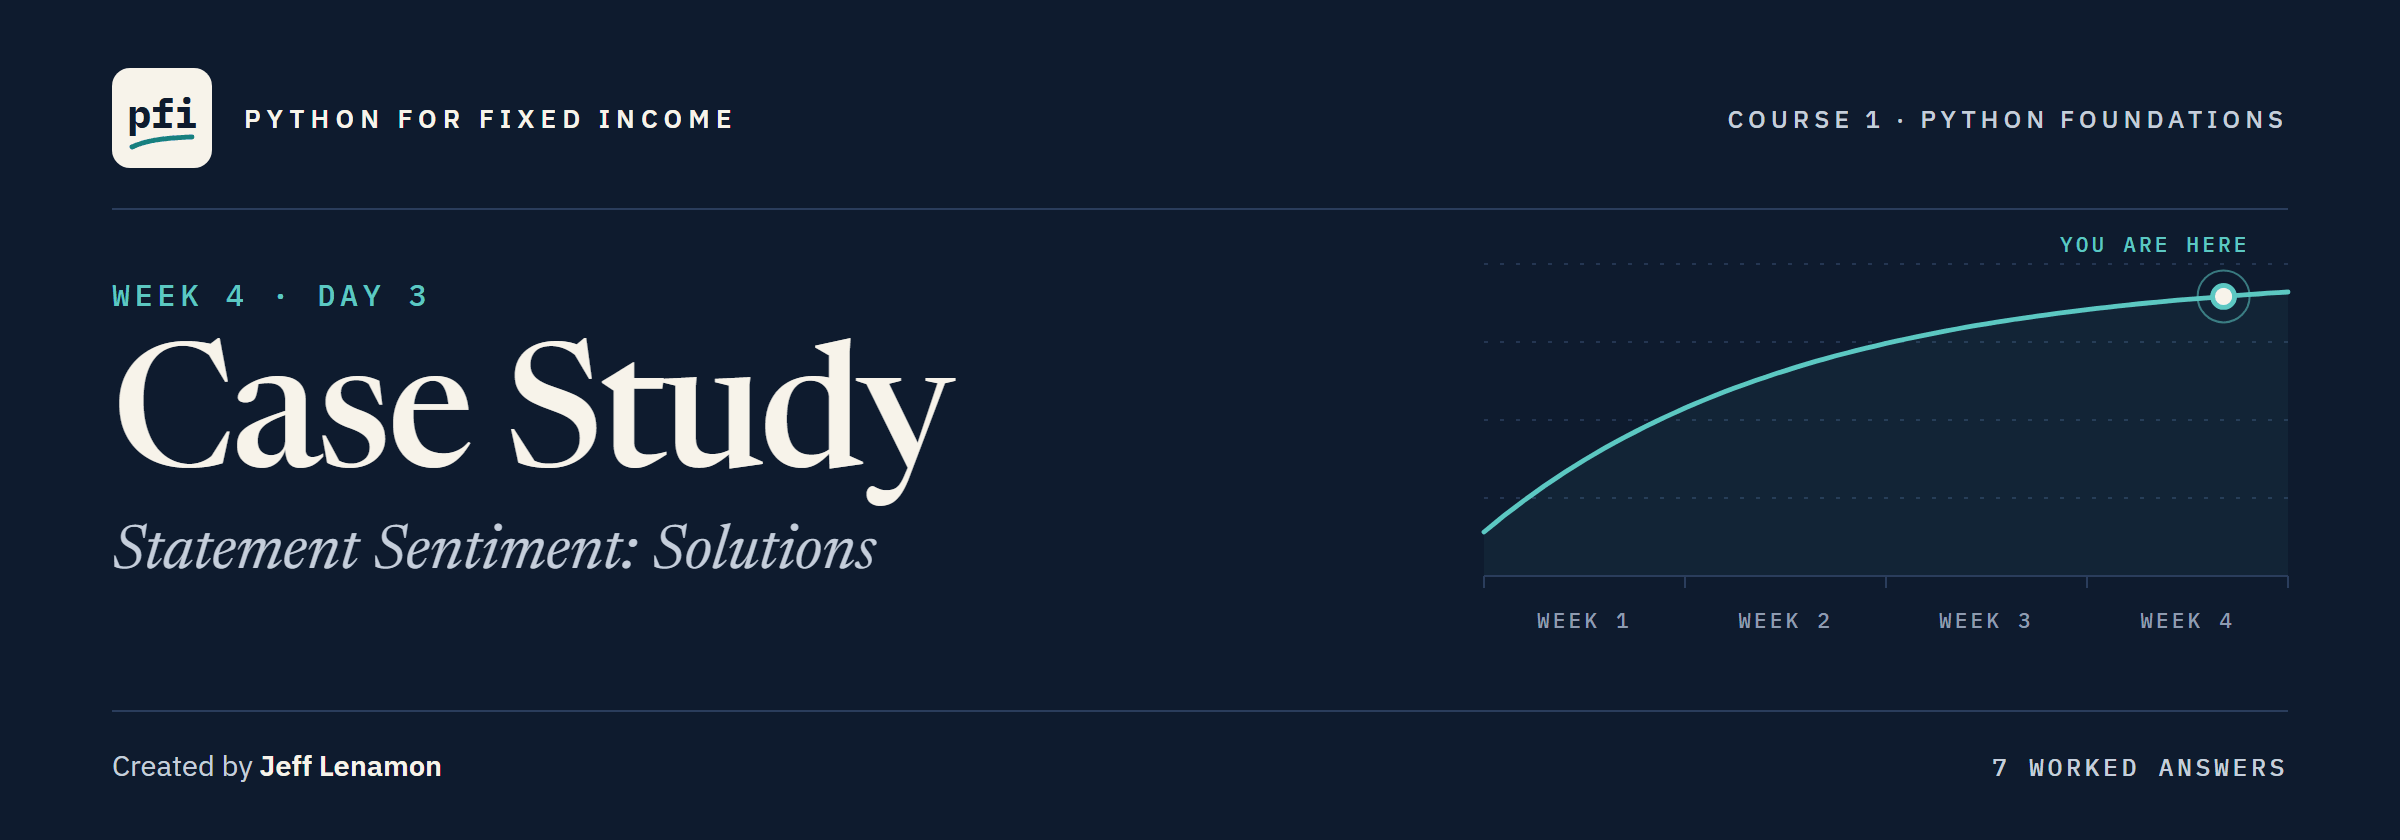

# Case Study: Statement Sentiment: Solutions

Week 4, Day 3. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day3/18_case_study_statement_sentiment_solutions.ipynb)

The statements are public text from the Board of Governors of the Federal Reserve System, retrieved 2026-10-03; the teaching notebook gives the source and reuse terms. Every answer is a count or a score from a stated list.

## Exercises

Each answer is followed by the check cell from the teaching notebook.
Run the next two cells first: the first defines `check`; the second loads the statements, the four lists, and the functions.

In [1]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [2]:
import os
import re

import matplotlib.pyplot as plt
import nltk
import pandas as pd
import seaborn as sns
from nltk.corpus import stopwords
from nltk.sentiment import SentimentIntensityAnalyzer

# the house theme, as in the lesson
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
nltk.download('stopwords', quiet=True)
nltk.download('vader_lexicon', quiet=True)
stop_words = stopwords.words('english')
analyzer = SentimentIntensityAnalyzer()


def clean(text):
    text = re.sub(r'[^a-z\s]', ' ', text.lower())
    return re.sub(r'\s+', ' ', text).strip().split(' ')


def remove_stop_words(tokens):
    return [token for token in tokens if token not in stop_words]


def list_score(tokens, plus_words, minus_words):
    plus = len([token for token in tokens if token in plus_words])
    minus = len([token for token in tokens if token in minus_words])
    return (plus - minus) / len(tokens) * 100


def vader_score(text):
    return analyzer.polarity_scores(text)['compound']


positive_words = ['good', 'strong', 'better', 'gains', 'support', 'progress', 'improved',
                  'improvement', 'confidence', 'growth', 'solid', 'stable',
                  'recovery', 'benefit']
negative_words = ['bad', 'weak', 'worse', 'risks', 'inflation', 'unemployment', 'pressures',
                  'restrictive', 'uncertain', 'hardship', 'decline', 'loss', 'debt', 'lower']
firm_words = ['expanding', 'expand', 'expanded', 'solid', 'strong', 'robust', 'strengthened',
              'picked', 'resilient', 'gains']
soft_words = ['slowed', 'moderated', 'declined', 'weak', 'weakness', 'weaker', 'softened']

# a fresh copy of the statements; in Colab, from GitHub
if os.path.exists('../../../data/fomc_statements.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
statements = pd.read_csv(data_folder + 'fomc_statements.csv')
statements['kept'] = statements['text'].apply(clean).apply(remove_stop_words)
statements['n_kept'] = statements['kept'].str.len()
print(statements.shape, statements['n_kept'].sum())

(46, 5) 10204


### Exercise 1

Q. For 2024-03-20, print the hits on each general list. Store the negative count in **ex1_negative** and the score, to 2 decimals, in **ex1_score**.

In [3]:
# the kept tokens of the statement, and the hits on each list, printed
tokens = statements.loc[statements['date'] == '2024-03-20', 'kept'].iloc[0]
negative_hits = [token for token in tokens if token in negative_words]
print([token for token in tokens if token in positive_words])
print(negative_hits)
ex1_negative = len(negative_hits)
ex1_score = round(list_score(tokens, positive_words, negative_words), 2)
print(len(tokens), ex1_negative, ex1_score)

['solid', 'gains', 'strong', 'better', 'support', 'confidence']
['unemployment', 'inflation', 'inflation', 'risks', 'inflation', 'uncertain', 'inflation', 'risks', 'risks', 'inflation', 'debt', 'inflation', 'risks', 'inflation', 'pressures', 'inflation']
202 16 -4.95


6 positive and 16 negative hits on 202 tokens: a net of -10, so -4.95 per 100.
8 of the 16 are `inflation`.

In [4]:
check('Exercise 1 negative hits', ex1_negative, 16)
check('Exercise 1 score', ex1_score, -4.95)

Exercise 1 negative hits: correct
Exercise 1 score: correct


### Exercise 2

Q. Take `inflation` off the negative list and score all 46 again. Store the number below zero in **ex2_below**, and the lowest statement's date and score, to 2 decimals, in **ex2_date** and **ex2_lowest**.

In [5]:
# the negative list without one word, scored through a lambda
negative_without = [word for word in negative_words if word != 'inflation']
without = statements['kept'].apply(
    lambda tokens: list_score(tokens, positive_words, negative_without))
ex2_below = int((without < 0).sum())
ex2_date = statements.loc[without.idxmin(), 'date']
ex2_lowest = round(without.min(), 2)
print(ex2_below, ex2_date, ex2_lowest, round(without.mean(), 2))

34 2025-09-17 -3.47 -0.76


34 below zero, against 42 with the full list; the lowest moves to 2025-09-17 at -3.47.
One word of 28 moved 8 statements across zero.

In [6]:
check('Exercise 2 statements below zero', ex2_below, 34)
check('Exercise 2 date of the lowest', ex2_date, '2025-09-17')
check('Exercise 2 lowest score', ex2_lowest, -3.47)

Exercise 2 statements below zero: correct
Exercise 2 date of the lowest: correct
Exercise 2 lowest score: correct


### Exercise 3

Q. Score each statement's **first paragraph** (up to the first `'\n'`) with VADER. Store the number below zero in **ex3_below** and the lowest one's date in **ex3_date**.

In [7]:
# the text up to the first line break, scored raw
first_paragraph = statements['text'].apply(lambda text: text.split('\n')[0])
vader_first = first_paragraph.apply(vader_score)
ex3_below = int((vader_first < 0).sum())
ex3_date = statements.loc[vader_first.idxmin(), 'date']
print(ex3_below, (vader_first > 0.9).sum(), ex3_date, vader_first.min())
print(first_paragraph[vader_first.idxmin()])

15 0 2025-10-29 -0.4404
Available indicators suggest that economic activity has been expanding at a moderate pace. Job gains have slowed this year, and the unemployment rate has edged up but remained low through August; more recent indicators are consistent with these developments. Inflation has moved up since earlier in the year and remains somewhat elevated.


15 first paragraphs below zero, against 12 whole statements; none above 0.9, against 15.
A shorter text holds fewer rated words, so the compound is pressed less hard to the ends.

In [8]:
check('Exercise 3 first paragraphs below zero', ex3_below, 15)
check('Exercise 3 date of the lowest', ex3_date, '2025-10-29')

Exercise 3 first paragraphs below zero: correct
Exercise 3 date of the lowest: correct


### Exercise 4

Q. Store the correlation of `n_kept` with the domain score in **ex4_corr**, and the shortest statement's z-score of `n_kept` in **ex4_z**, both to 2 decimals. Draw one against the other.

-0.75 -2.57 -0.55


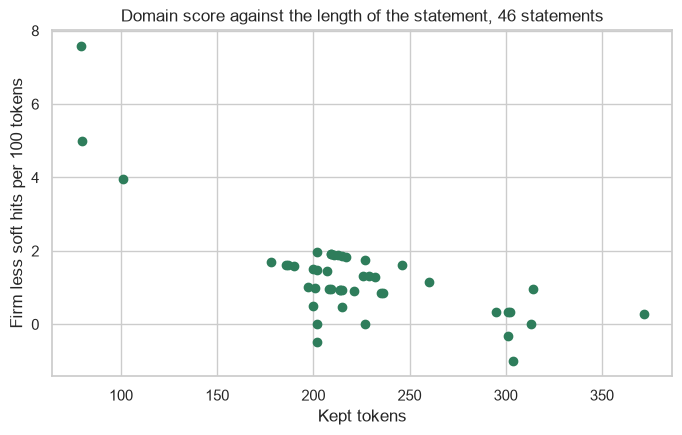

In [9]:
# the domain score, then how much of it is length
domain = statements['kept'].apply(lambda tokens: list_score(tokens, firm_words, soft_words))
ex4_corr = round(statements['n_kept'].corr(domain), 2)
z_length = (statements['n_kept'] - statements['n_kept'].mean()) / statements['n_kept'].std()
ex4_z = round(z_length.min(), 2)
longer = statements['n_kept'] > 101
print(ex4_corr, ex4_z, round(statements['n_kept'][longer].corr(domain[longer]), 2))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(statements['n_kept'], domain)
ax.set_title('Domain score against the length of the statement, 46 statements')
ax.set_xlabel('Kept tokens')
ax.set_ylabel('Firm less soft hits per 100 tokens')
plt.show()

-0.75: the shorter the statement, the higher the score; the shortest is 2.57 standard deviations below the mean length.

Without the three shortest, -0.55: per 100 tokens did not take length out.

Keep the count beside every average.

In [10]:
check('Exercise 4 correlation', ex4_corr, -0.75)
check('Exercise 4 z-score of the shortest', ex4_z, -2.57)

Exercise 4 correlation: correct
Exercise 4 z-score of the shortest: correct


### Exercise 5

Q. Write `hit_counts(tokens, word_list)`, returning a dict of each listed word found in `tokens` with its count; leave out a word with no hits.

In [11]:
def hit_counts(tokens, word_list):
    """Return a dict: each word of word_list found in tokens, with its count."""
    counts = {}
    for token in tokens:
        if token in word_list:
            # get() gives the count so far, or 0 the first time
            counts[token] = counts.get(token, 0) + 1
    return counts


# a check on a list short enough to count by eye
typed = hit_counts(['inflation', 'rate', 'inflation'], ['inflation'])
assert typed == {'inflation': 2}, 'wrong count'
tokens = statements.loc[statements['date'] == '2024-03-20', 'kept'].iloc[0]
print(hit_counts(tokens, negative_words))

{'unemployment': 1, 'inflation': 8, 'risks': 4, 'uncertain': 1, 'debt': 1, 'pressures': 1}


16 negative hits, Exercise 1's count, now word by word.
In Excel, the 202 tokens in B2:B203: `=COUNTIF(B2:B203, "inflation")` returns 8.

In [12]:
# the kept tokens of the statement of 2024-03-20
tokens_0320 = statements.loc[statements['date'] == '2024-03-20', 'kept'].iloc[0]
typed = ['inflation', 'rate', 'inflation', 'gains', 'risks']
check('Exercise 5 typed list', hit_counts(typed, ['inflation', 'risks']),
      {'inflation': 2, 'risks': 1})
check('Exercise 5 negative hits of 2024-03-20', hit_counts(tokens_0320, negative_words),
      {'inflation': 8, 'risks': 4, 'unemployment': 1,
       'uncertain': 1, 'debt': 1, 'pressures': 1})

Exercise 5 typed list: correct
Exercise 5 negative hits of 2024-03-20: correct


### Exercise 6

Q. Write `label_score(compound, cutoff)` with no default cut-off. Label every raw-text VADER score at 0.5; store the positive and neutral counts in **ex6_positive** and **ex6_neutral**.

In [13]:
def label_score(compound, cutoff):
    # at or above the cut-off positive, at or below minus it negative, else neutral
    if compound >= cutoff:
        return 'positive'
    elif compound <= -cutoff:
        return 'negative'
    return 'neutral'


# VADER on the raw text, then a label at 0.5
labels = statements['text'].apply(vader_score).apply(label_score, cutoff=0.5)
ex6_positive = int((labels == 'positive').sum())
ex6_neutral = int((labels == 'neutral').sum())
print(labels.value_counts())

text
positive    29
neutral      9
negative     8
Name: count, dtype: int64


29 positive, 9 neutral, 8 negative: the lesson's row for 0.5.
In Excel: `=IF(E2>=0.5,"positive",IF(E2<=-0.5,"negative","neutral"))`, filled down.

In [14]:
check('Exercise 6 label of 0.6', label_score(0.6, 0.5), 'positive')
check('Exercise 6 label of -0.5', label_score(-0.5, 0.5), 'negative')
check('Exercise 6 label of 0.2', label_score(0.2, 0.5), 'neutral')
check('Exercise 6 positive statements', ex6_positive, 29)
check('Exercise 6 neutral statements', ex6_neutral, 9)

Exercise 6 label of 0.6: correct
Exercise 6 label of -0.5: correct
Exercise 6 label of 0.2: correct
Exercise 6 positive statements: correct
Exercise 6 neutral statements: correct


### Exercise 7: AI check

The assistant's code gave 0.4404 and 11 with no error.
The bug: it cleaned the text before scoring, a habit from token counts; VADER's rules read what cleaning removes.

The score was off by 0.36; the count by one, small enough to pass.

Check against the number, not roughly the number.

In [15]:
# VADER takes the text as published
statements['vader'] = statements['text'].apply(vader_score)

ex7_score = round(statements.loc[statements['date'] == '2025-06-18', 'vader'].iloc[0], 4)
ex7_below = int((statements['vader'] < 0).sum())
print(ex7_score, ex7_below)

0.802 12


In [16]:
check('Exercise 7 score of 2025-06-18', ex7_score, 0.802)
check('Exercise 7 statements below zero', ex7_below, 12)

Exercise 7 score of 2025-06-18: correct
Exercise 7 statements below zero: correct


[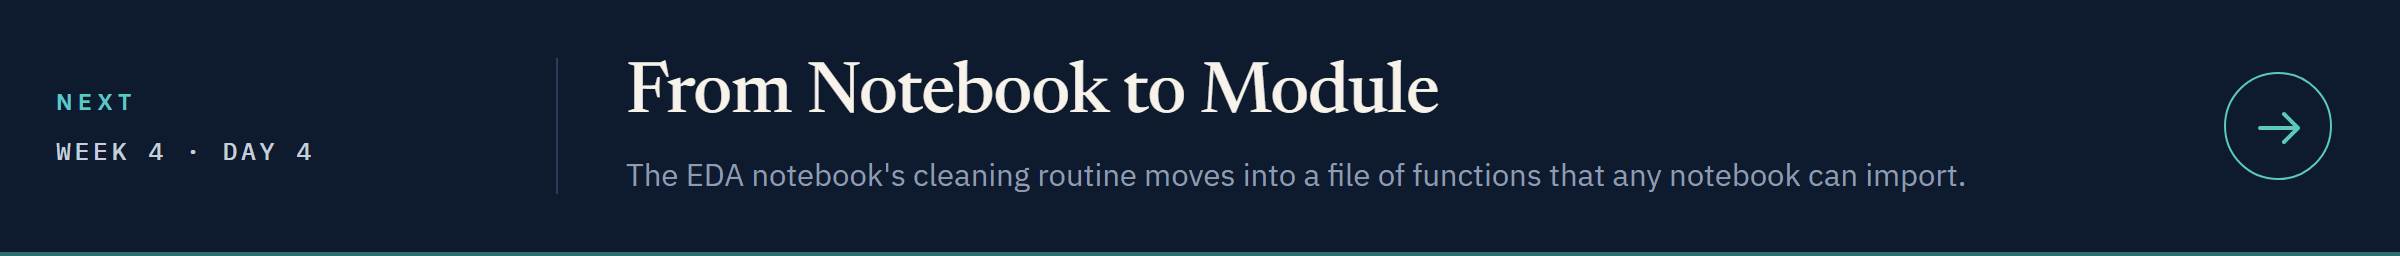](../day4/19_from_notebook_to_module.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day4/19_from_notebook_to_module.ipynb)